# Step 1: Create the inventory

In [119]:
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path("../")
VIDEO_DIR = PROJECT_ROOT / "data" / "raw" / "dolos_clips"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_CSV = OUTPUT_DIR / "video_inventory.csv"

print("Project root:", PROJECT_ROOT)
print("Video directory:", VIDEO_DIR)
print("Video directory exists:", VIDEO_DIR.exists())

if not VIDEO_DIR.exists():
    raise FileNotFoundError(
        f"Can't find {VIDEO_DIR}. Set PROJECT_ROOT to the root of your project repository."
    )

Project root: ..
Video directory: ..\data\raw\dolos_clips
Video directory exists: True


In [120]:
# Find videos recursively and create one row per file.
video_paths = sorted(
    p for p in VIDEO_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() == ".mp4"
)

rows = []
for p in video_paths:
    rows.append({
        "clip_id": p.stem,
        "file_name": p.name,
        "relative_path": str(p.relative_to(PROJECT_ROOT)),
        "size_bytes": p.stat().st_size,
    })

inventory = pd.DataFrame(rows, columns=["clip_id", "file_name", "relative_path", "size_bytes"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
inventory.to_csv(OUTPUT_CSV, index=False)

print(f"Video files found: {len(inventory):,}")
print(f"Inventory saved to: {OUTPUT_CSV}")
inventory.head(15)

Video files found: 1,416
Inventory saved to: ..\data\processed\video_inventory.csv


,clip_id,file_name,relative_path,size_bytes
0,AN_WILTY_EP15_lie10,AN_WILTY_EP15_lie10.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie10.mp4,161959
1,AN_WILTY_EP15_lie11,AN_WILTY_EP15_lie11.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie11.mp4,177524
2,AN_WILTY_EP15_lie12,AN_WILTY_EP15_lie12.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie12.mp4,237247
3,AN_WILTY_EP15_lie13,AN_WILTY_EP15_lie13.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie13.mp4,227258
4,AN_WILTY_EP15_lie14,AN_WILTY_EP15_lie14.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie14.mp4,328568
5,AN_WILTY_EP15_lie15,AN_WILTY_EP15_lie15.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie15.mp4,215926
6,AN_WILTY_EP15_lie16,AN_WILTY_EP15_lie16.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie16.mp4,380515
7,AN_WILTY_EP15_lie17,AN_WILTY_EP15_lie17.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie17.mp4,337405
8,AN_WILTY_EP15_lie18,AN_WILTY_EP15_lie18.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie18.mp4,222255
9,AN_WILTY_EP15_lie19,AN_WILTY_EP15_lie19.mp4,data\raw\dolos_clips\AN_WILTY_EP15_lie19.mp4,152471


In [121]:
# Check duplicate IDs / names. These are warnings to investigate, not automatic errors.
if inventory.empty:
    print("WARNING: no .mp4 files were found.")
else:
    duplicate_stems = inventory[inventory["clip_id"].duplicated(keep=False)].sort_values("clip_id")
    duplicate_names = inventory[inventory["file_name"].duplicated(keep=False)].sort_values("file_name")
    zero_byte = inventory[inventory["size_bytes"] == 0]

    print("Unique clip IDs:", inventory["clip_id"].nunique())
    print("Duplicate clip IDs:", len(duplicate_stems))
    print("Duplicate filenames:", len(duplicate_names))
    print("Zero-byte files:", len(zero_byte))

    if not duplicate_stems.empty:
        display(duplicate_stems)
    if not zero_byte.empty:
        display(zero_byte)

Unique clip IDs: 1416
Duplicate clip IDs: 0
Duplicate filenames: 0
Zero-byte files: 0


In [122]:
# Search common project folders for likely metadata/annotation files.
# This only lists candidates; it does not assume a file is the correct annotation source.
metadata_extensions = {".xlsx", ".xls", ".csv", ".tsv", ".txt", ".json", ".jsonl"}
search_roots = [PROJECT_ROOT / "data", PROJECT_ROOT / "configs"]
metadata_candidates = []
for root in search_roots:
    if root.exists():
        for p in root.rglob("*"):
            if p.is_file() and p.suffix.lower() in metadata_extensions:
                metadata_candidates.append({
                    "file_name": p.name,
                    "relative_path": str(p.relative_to(PROJECT_ROOT)),
                    "size_bytes": p.stat().st_size,
                })

metadata_df = pd.DataFrame(metadata_candidates)
if metadata_df.empty:
    print("No likely metadata files found under data/ or configs/.")
    print("Next action: retrieve the official DOLOS annotation/metadata package.")
else:
    display(metadata_df.sort_values("relative_path"))

,file_name,relative_path,size_bytes
0,video_inventory.csv,data\processed\video_inventory.csv,139896
1,subject_isolated_splits.csv,data\splits\subject_isolated_splits.csv,169142


# Step 2: Split and Extract audio

In [123]:
from pathlib import Path
import av , pandas as pd

CLIPS_DIR = Path("../data/raw/dolos_clips")
rows = []
for p in sorted(CLIPS_DIR.glob("*.mp4")):
    try:
        with av.open(str(p)) as c: d = c.duration / 1e6
    except Exception:
        d = float("nan")
    rows.append((p.stem.replace(" ", ""), d))
dur_df = pd.DataFrame(rows, columns=["clip_id", "dur_s"])
print(dur_df.dur_s.describe().round(1))
print((dur_df.dur_s > 15).sum(), "clips > 15 s |", (dur_df.dur_s > 45).sum(), "clips > 45 s")
print(dur_df.nlargest(20, "dur_s"))

count    1416.0
mean        5.6
std        10.0
min         2.0
25%         4.0
50%         5.0
75%         6.0
max       300.0
Name: dur_s, dtype: float64
10 clips > 15 s | 4 clips > 45 s
                      clip_id       dur_s
698       LS_WILTY_EP3_truth5  300.000000
394      BRI_WILTY_EP61_lie_6  181.000000
170      AN_WILTY_EP22_truth1  123.000000
815        LS_WILTY_EP75_lie2   48.000000
390     BRI_WILTY_EP61_lie_36   41.000000
817        LS_WILTY_EP75_lie4   32.000000
808       LS_WILTY_EP73_true5   23.000000
829       LS_WILTY_EP76_lie14   22.000000
972        SB_WILTY_EP34_lie8   19.000000
1070      SB_WILTY_EP42_lie15   16.000000
955        SB_WILTY_EP33_lie5   14.000000
1043     SB_WILTY_EP38_truth3   14.000000
775        LS_WILTY_EP72_lie6   12.000000
1025    SB_WILTY_EP37_truth13   12.000000
1038       SB_WILTY_EP38_lie4   12.000000
1088    SB_WILTY_EP42_truth14   12.000000
519   BRI_WILTY_EP66_truth_15   11.020835
780       LS_WILTY_EP72_true2   11.000000
796       LS_

In [124]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit


INPUT_CSV = Path("../data/processed/video_inventory.csv")
OUTPUT_CSV = Path("../data/splits/subject_isolated_splits.csv")

def create_zero_leakage_splits():
    # 1. Load the dataset
    df = pd.read_csv(INPUT_CSV)
    
    # 2. Extract Subject Identity
    # Converts 'AN_WILTY_EP15_lie10' -> 'AN_WILTY_EP15'
    df['subject_id'] = df['clip_id'].apply(lambda x: "_".join(str(x).split('_')[:-1]))
    
    print(f"Total Clips: {len(df)}")
    print(f"Unique Subjects/Episodes: {df['subject_id'].nunique()}")

    # 3. First Split: Separate Train (70%) vs Temp (30%)
    gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_idx, temp_idx = next(gss1.split(df, groups=df['subject_id']))
    
    # 4. Second Split: Separate Temp into Val (15%) and Test (15%)
    temp_df = df.iloc[temp_idx].copy()
    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    val_idx_temp, test_idx_temp = next(gss2.split(temp_df, groups=temp_df['subject_id']))
    
    # Map temp indices back to original dataframe
    val_idx = temp_idx[val_idx_temp]
    test_idx = temp_idx[test_idx_temp]

    # Assign split labels
    df.loc[train_idx, 'split'] = 'train'
    df.loc[val_idx, 'split'] = 'val'
    df.loc[test_idx, 'split'] = 'test'

    # Display split statistics
    print("\n--- Split Statistics ---")
    print(df['split'].value_counts())
    print("\n--- Unique Subjects per Split ---")
    print(df.groupby('split')['subject_id'].nunique())

    # Save mapping
    OUTPUT_CSV.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(OUTPUT_CSV, index=False)
    print(f"\nZero-leakage splits saved to: {OUTPUT_CSV}")

if __name__ == "__main__":
    create_zero_leakage_splits()

Total Clips: 1416
Unique Subjects/Episodes: 77

--- Split Statistics ---
split
train    1017
test      200
val       199
Name: count, dtype: int64

--- Unique Subjects per Split ---
split
test     12
train    53
val      12
Name: subject_id, dtype: int64

Zero-leakage splits saved to: ..\data\splits\subject_isolated_splits.csv


In [125]:
import pandas as pd
df = pd.read_csv(OUTPUT_CSV)
train_df = df[df['split'] == 'train'].copy()
print(f"EDA restricted to {len(train_df)} training clips.")

EDA restricted to 1017 training clips.


## Extracting audio

In [126]:
from pathlib import Path
import subprocess
import pandas as pd
import soundfile as sf 

PROJECT_ROOT = Path("../")
SPLITS_CSV = PROJECT_ROOT / "data" / "splits" / "subject_isolated_splits.csv"
AUDIO_TRAIN_DIR = PROJECT_ROOT / "data" / "processed" / "audio_train"
AUDIO_TRAIN_DIR.mkdir(parents=True, exist_ok=True)

# Load split dataset and filter strictly for training subjects
df = pd.read_csv(SPLITS_CSV)
train_df = df[df['split'] == 'train'].copy()

audio_metadata = []
print(f"Extracting and inspecting audio streams for {len(train_df)} training clips...")

for _, row in train_df.iterrows():
    clip_id = row['clip_id']
    video_path = PROJECT_ROOT / row['relative_path']
    wav_output_path = AUDIO_TRAIN_DIR / f"{clip_id}.wav"
    
    try:
        # Step 1: Extract audio using a direct ffmpeg subprocess command (if it doesn't already exist)
        if not wav_output_path.exists():
            cmd = [
                "ffmpeg", "-y", 
                "-i", str(video_path), 
                "-ar", "16000",       # Resample to 16kHz standard
                "-ac", "1",           # Convert to mono
                "-vn",                # Drop video stream
                str(wav_output_path)
            ]
            subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)
            
        # Step 2: Read WAV properties using soundfile for clean EDA metadata collection
        if wav_output_path.exists():
            info = sf.info(str(wav_output_path))
            sample_rate = info.samplerate
            channels = info.channels
            duration_sec = info.duration
            num_samples = info.frames
            
            audio_metadata.append({
                "clip_id": clip_id,
                "audio_path": str(wav_output_path.relative_to(PROJECT_ROOT)),
                "sample_rate": sample_rate,
                "channels": channels,
                "duration_sec": duration_sec,
                "num_samples": num_samples
            })
    except Exception as e:
        print(f"Error processing audio for {clip_id}: {e}")

# Create summary DataFrame for your acoustic EDA notebook
audio_eda_df = pd.DataFrame(audio_metadata)
print(f"\nSuccessfully processed {len(audio_eda_df)} training audio files to `{AUDIO_TRAIN_DIR}`.")

Extracting and inspecting audio streams for 1017 training clips...

Successfully processed 1017 training audio files to `..\data\processed\audio_train`.


# Step 3: EDA

In [127]:
display(audio_eda_df.describe())

,sample_rate,channels,duration_sec,num_samples
count,1017.0,1017.0,1017.000000,1.017000e+03
mean,16000.0,1.0,5.834808,9.335693e+04
std,0.0,0.0,11.714545,1.874327e+05
min,16000.0,1.0,2.000000,3.200000e+04
25%,16000.0,1.0,4.000000,6.400000e+04
50%,16000.0,1.0,5.000000,8.000000e+04
75%,16000.0,1.0,6.000000,9.600000e+04
max,16000.0,1.0,300.000000,4.800000e+06


## RMS Energy & Amplitude Profiling

computing RMS energy and peak amplitudes for 1017 training audio clips
Mean RMS Energy (Active Speech): 0.0827
Mean RMS Energy (Silent Baseline): 0.0101


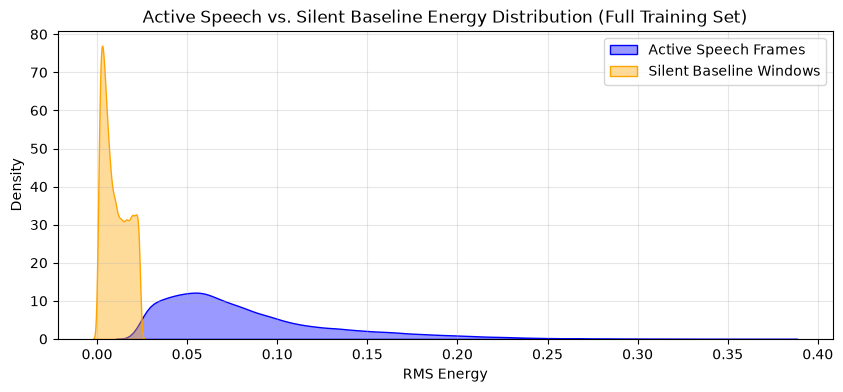

In [128]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

audio_dir = PROJECT_ROOT / "data" / "processed" / "audio_train"

rms_values = []
peak_amplitudes = []

print(f"computing RMS energy and peak amplitudes for {len(audio_eda_df)} training audio clips")
for _, row in audio_eda_df.iterrows(): 
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # Compute Root Mean Square (RMS) energy across frames
        rms = librosa.feature.rms(y=y)[0]
        rms_values.extend(rms)
        peak_amplitudes.append(np.max(np.abs(y)))

rms_values = np.array(rms_values)

# Active speech vs Silent thresholding (using dynamic energy percentiles)
silence_threshold = np.percentile(rms_values, 20)
active_speech = rms_values[rms_values > silence_threshold]
silent_windows = rms_values[rms_values <= silence_threshold]

print(f"Mean RMS Energy (Active Speech): {np.mean(active_speech):.4f}")
print(f"Mean RMS Energy (Silent Baseline): {np.mean(silent_windows):.4f}")

# Plotting Energy Distribution
plt.figure(figsize=(10, 4))
sns.kdeplot(active_speech, label='Active Speech Frames', fill=True, color='blue', alpha=0.4)
sns.kdeplot(silent_windows, label='Silent Baseline Windows', fill=True, color='orange', alpha=0.4)
plt.title("Active Speech vs. Silent Baseline Energy Distribution (Full Training Set)")
plt.xlabel("RMS Energy")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## SNR & Clipping Inspection

running SNR and clipping analysis across 1017 training audio clips
Clips with potential clipping (distortion): 0 out of 1017 training clips.
Estimated SNR (dB) - Mean: 30.58 dB | Std: 5.05 dB


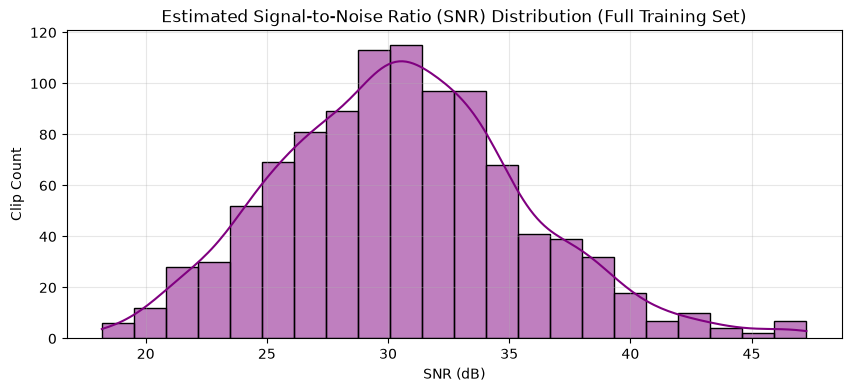

In [129]:
snr_estimates = []
clipping_counts = 0

print(f"running SNR and clipping analysis across {len(audio_eda_df)} training audio clips")
for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # Check for clipping (amplitude >= 0.99)
        if np.any(np.abs(y) >= 0.99):
            clipping_counts += 1
            
        # Approximate SNR estimation using signal power vs noise floor estimation
        signal_power = np.mean(y**2)
        noise_floor = np.percentile(y**2, 10) # bottom 10% energy as noise floor approximation
        if noise_floor > 0:
            snr = 10 * np.log10(signal_power / noise_floor)
            snr_estimates.append(snr)

print(f"Clips with potential clipping (distortion): {clipping_counts} out of {len(audio_eda_df)} training clips.")
print(f"Estimated SNR (dB) - Mean: {np.mean(snr_estimates):.2f} dB | Std: {np.std(snr_estimates):.2f} dB")

plt.figure(figsize=(10, 4))
sns.histplot(snr_estimates, kde=True, color='purple')
plt.title("Estimated Signal-to-Noise Ratio (SNR) Distribution (Full Training Set)")
plt.xlabel("SNR (dB)")
plt.ylabel("Clip Count")
plt.grid(True, alpha=0.3)
plt.show()

## Global Normalization Statistics

In [130]:
import torch
import torchaudio.transforms as T
import soundfile as sf

print(f"computing global normalization parameters (mean & std) for log-mel spectrograms across all {len(audio_eda_df)} training clips")

mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=533,  
    n_mels=128      
)

all_mels = []
for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        # Read using soundfile to completely avoid torchcodec backend issues
        y, sr = sf.read(str(wav_path))
        
        # Convert NumPy array to PyTorch tensor and adjust shape to (channels, time)
        waveform = torch.tensor(y, dtype=torch.float32)
        if waveform.ndim == 1:
            waveform = waveform.unsqueeze(0)  # Shape: (1, time) for mono
        else:
            waveform = waveform.t()          # Shape: (channels, time) if multi-channel
            
        mel_spec = mel_transform(waveform)
        log_mel = torch.log(mel_spec + 1e-9)
        all_mels.append(log_mel)

# Concatenate along time axis to compute global mean and std
concat_mels = torch.cat(all_mels, dim=-1)
global_mean = concat_mels.mean().item()
global_std = concat_mels.std().item()

print(f"Computed Training Log-Mel Mean (mu): {global_mean:.4f}")
print(f"Computed Training Log-Mel Std (sigma): {global_std:.4f}")

computing global normalization parameters (mean & std) for log-mel spectrograms across all 1017 training clips
Computed Training Log-Mel Mean (mu): -1.8038
Computed Training Log-Mel Std (sigma): 3.3174


## Removing outliers from the dataset

In [131]:
import torch
import torchaudio.transforms as T
import soundfile as sf

# Identify and remove outliers (> 60 seconds) from audio_eda_df
outliers = audio_eda_df[audio_eda_df['duration_sec'] > 60.0]
print(f"Found {len(outliers)} outlier clip(s) to remove:")
display(outliers[['clip_id', 'duration_sec']])

# Delete outlier .wav files from disk
for _, row in outliers.iterrows():
    wav_path = PROJECT_ROOT / row['audio_path']
    if wav_path.exists():
        wav_path.unlink()
        print(f"Deleted outlier file: {wav_path.name}")

# Filter audio_eda_df to keep only valid clean clips
audio_eda_df = audio_eda_df[audio_eda_df['duration_sec'] <= 60.0].reset_index(drop=True)
print(f"\nClean training partition size: {len(audio_eda_df)} clips remaining.")

Found 3 outlier clip(s) to remove:


,clip_id,duration_sec
109,AN_WILTY_EP22_truth1,123.0
253,BRI_WILTY_EP61_lie_6,181.0
437,LS_WILTY_EP3_truth5,300.0


Deleted outlier file: AN_WILTY_EP22_truth1.wav
Deleted outlier file: BRI_WILTY_EP61_lie_6.wav
Deleted outlier file: LS_WILTY_EP3_truth5.wav

Clean training partition size: 1014 clips remaining.


### Re-computing global normalization parameters

In [132]:
mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=533,  
    n_mels=128      
)

all_mels = []
for _, row in audio_eda_df.iterrows():
    wav_path = PROJECT_ROOT / row['audio_path']
    if wav_path.exists():
        y, sr = sf.read(str(wav_path))
        waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0)  # Shape: (1, time)
        
        mel_spec = mel_transform(waveform)
        log_mel = torch.log(mel_spec + 1e-9)
        all_mels.append(log_mel)

# Concatenate along time axis to compute clean global stats
concat_mels = torch.cat(all_mels, dim=-1)
global_mean = concat_mels.mean().item()
global_std = concat_mels.std().item()

print(f"Computed Clean Training Log-Mel Mean (mu): {global_mean:.4f}")
print(f"Computed Clean Training Log-Mel Std (sigma): {global_std:.4f}")

Computed Clean Training Log-Mel Mean (mu): -1.9857
Computed Clean Training Log-Mel Std (sigma): 3.2916


### Re-computing RMS, Amplitude, SNR & Clipping

===  ACROSS ALL 1014 CLEAN TRAINING CLIPS ===

--- Cleaned Energy Metrics ---
Mean RMS Energy (Active Speech): 0.0779
Mean RMS Energy (Silent Baseline): 0.0093

--- Cleaned Signal Quality Metrics ---
Clips with potential clipping: 0 out of 1014 clips.
Estimated SNR (dB) - Mean: 30.59 dB | Std: 5.06 dB


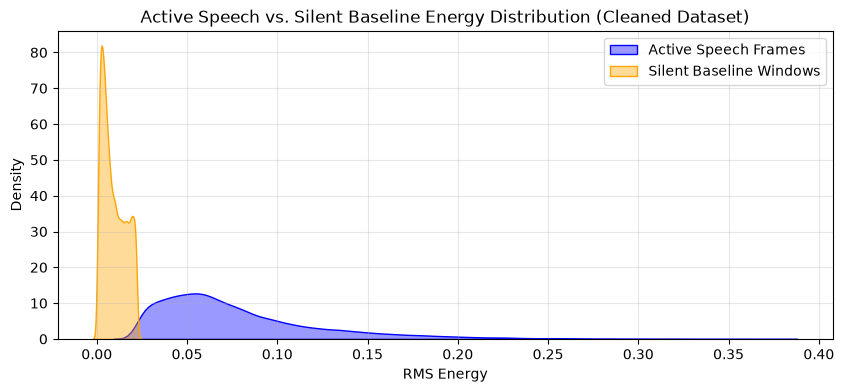

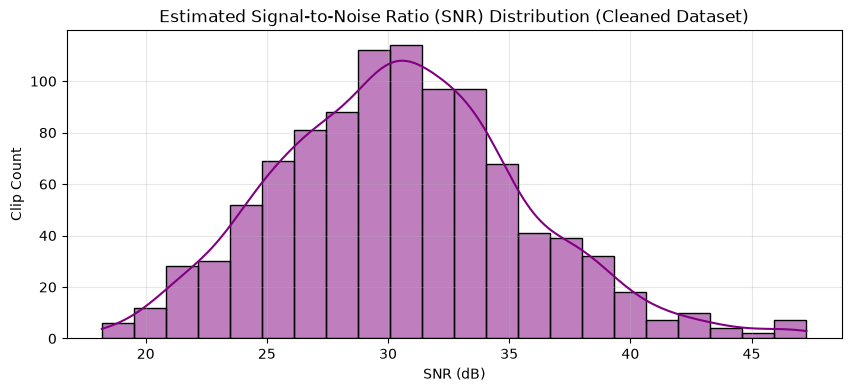

In [133]:
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

audio_dir = PROJECT_ROOT / "data" / "processed" / "audio_train"

rms_values = []
peak_amplitudes = []
snr_estimates = []
clipping_counts = 0

print(f"===  ACROSS ALL {len(audio_eda_df)} CLEAN TRAINING CLIPS ===")

for _, row in audio_eda_df.iterrows():
    wav_path = audio_dir / f"{row['clip_id']}.wav"
    if wav_path.exists():
        y, sr = librosa.load(str(wav_path), sr=16000)
        
        # 1. RMS Energy & Peak Amplitude
        rms = librosa.feature.rms(y=y)[0]
        rms_values.extend(rms)
        peak_amplitudes.append(np.max(np.abs(y)))
        
        # 2. Clipping check (amplitude >= 0.99)
        if np.any(np.abs(y) >= 0.99):
            clipping_counts += 1
            
        # 3. SNR estimation using signal power vs noise floor estimation (bottom 10% energy)
        signal_power = np.mean(y**2)
        noise_floor = np.percentile(y**2, 10)
        if noise_floor > 0:
            snr = 10 * np.log10(signal_power / noise_floor)
            snr_estimates.append(snr)

rms_values = np.array(rms_values)
snr_estimates = np.array(snr_estimates)

# Active speech vs Silent thresholding (using dynamic energy percentiles)
silence_threshold = np.percentile(rms_values, 20)
active_speech = rms_values[rms_values > silence_threshold]
silent_windows = rms_values[rms_values <= silence_threshold]

print(f"\n--- Cleaned Energy Metrics ---")
print(f"Mean RMS Energy (Active Speech): {np.mean(active_speech):.4f}")
print(f"Mean RMS Energy (Silent Baseline): {np.mean(silent_windows):.4f}")

print(f"\n--- Cleaned Signal Quality Metrics ---")
print(f"Clips with potential clipping: {clipping_counts} out of {len(audio_eda_df)} clips.")
print(f"Estimated SNR (dB) - Mean: {np.mean(snr_estimates):.2f} dB | Std: {np.std(snr_estimates):.2f} dB")

# --- Plot 1: Active Speech vs. Silent Baseline Energy Distribution ---
plt.figure(figsize=(10, 4))
sns.kdeplot(active_speech, label='Active Speech Frames', fill=True, color='blue', alpha=0.4)
sns.kdeplot(silent_windows, label='Silent Baseline Windows', fill=True, color='orange', alpha=0.4)
plt.title("Active Speech vs. Silent Baseline Energy Distribution (Cleaned Dataset)")
plt.xlabel("RMS Energy")
plt.ylabel("Density")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- Plot 2: Estimated Signal-to-Noise Ratio (SNR) Distribution ---
plt.figure(figsize=(10, 4))
sns.histplot(snr_estimates, kde=True, color='purple')
plt.title("Estimated Signal-to-Noise Ratio (SNR) Distribution (Cleaned Dataset)")
plt.xlabel("SNR (dB)")
plt.ylabel("Clip Count")
plt.grid(True, alpha=0.3)
plt.show()

Using direct parameters -> Sample Rate: 16000 Hz, N_Mels: 128, Hop Length: 256


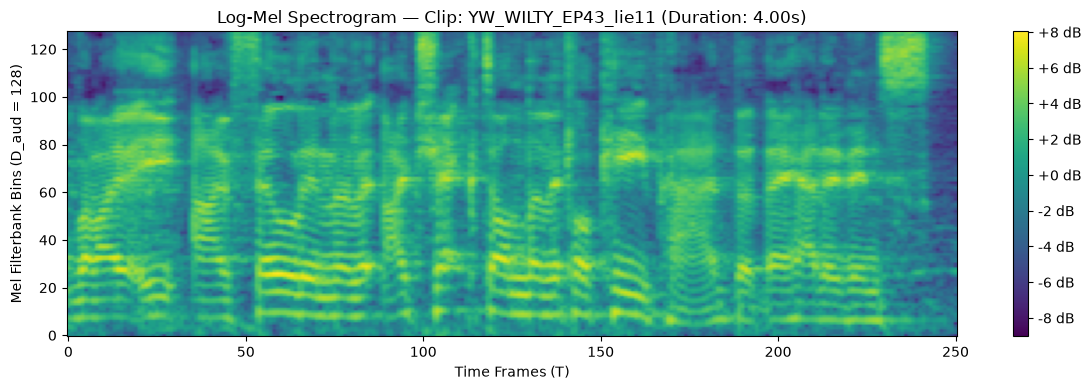

Extracted feature tensor shape: torch.Size([1, 128, 251])
Target format validation -> Expected feature dimensions match D_aud=128.


In [134]:
import torch
import torchaudio.transforms as T
import soundfile as sf
import matplotlib.pyplot as plt

# ==========================================
# Explicit Configuration Parameters
# ==========================================
SAMPLE_RATE = 16000  # Default target sample rate (adjust if needed, e.g., 22050)
N_FFT = 1024
HOP_LENGTH = 256     # Adjust hop length as needed for your time resolution
N_MELS = 128         # Target feature dimension D_aud = 128

print(f"Using direct parameters -> Sample Rate: {SAMPLE_RATE} Hz, N_Mels: {N_MELS}, Hop Length: {HOP_LENGTH}")

# 1. Pick a random clean training clip from audio_eda_df
sample_row = audio_eda_df.sample(n=1, random_state=42).iloc[0]
wav_path = PROJECT_ROOT / sample_row['audio_path']

# 2. Read audio using soundfile
y, sr = sf.read(str(wav_path))

# Resample or handle sample rate conversion if `sr` != `SAMPLE_RATE` is required, 
# or ensure `y` matches the expected SAMPLE_RATE.
waveform = torch.tensor(y, dtype=torch.float32).unsqueeze(0)  # Shape: (1, time)

# 3. Define Log-Mel Spectrogram transform using direct specifications
mel_transform = T.MelSpectrogram(
    sample_rate=SAMPLE_RATE,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,  
    n_mels=N_MELS            # D_aud = 128
)

mel_spec = mel_transform(waveform)
log_mel_spec = torch.log(mel_spec + 1e-9) # Stabilize log

# 4. Plot the Log-Mel Spectrogram
plt.figure(figsize=(12, 4))
plt.imshow(log_mel_spec[0].numpy(), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title(f"Log-Mel Spectrogram — Clip: {sample_row['clip_id']} (Duration: {sample_row['duration_sec']:.2f}s)")
plt.xlabel("Time Frames (T)")
plt.ylabel(f"Mel Filterbank Bins (D_aud = {N_MELS})")
plt.tight_layout()
plt.show()

print(f"Extracted feature tensor shape: {log_mel_spec.shape}")
print(f"Target format validation -> Expected feature dimensions match D_aud={N_MELS}.")